<a href="https://colab.research.google.com/github/kosaquito/AprendizajeAutomatico1/blob/main/ISSD_AA1_Regularizacion_Subajuste_Sobreajuste_Resuelto_Martinez_Martin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regularización, Subajuste y Sobreajuste en Regresión

Este notebook continúa el taller de **Introducción a la Regresión Lineal con Scikit-Learn**. Ahí ya conocimos `LinearRegression`, aprendimos a dividir datos en entrenamiento y prueba, a evaluar modelos con MAE, MSE, RMSE y R², y tuvimos una primera introducción a la regularización (Ridge y Lasso) y a `StandardScaler`.

En este taller vamos a profundizar tres ideas que quedaron pendientes:

1. **Regularización aplicada a un problema real:** vamos a usar un dataset de regresión ya incluido en `scikit-learn` y vamos a comprobar, con números y gráficos, que Ridge y Lasso pueden mejorar la capacidad de generalización de un modelo frente a la regresión lineal común.
2. **Subajuste y sobreajuste (*underfitting* y *overfitting*):** vamos a definir estos conceptos con precisión y los vamos a visualizar entrenando modelos de distinta complejidad sobre los mismos datos.
3. **Redes neuronales como "caja negra":** vamos a usar un `MLPRegressor` (una red neuronal simple) sin entrar en el detalle matemático de cómo funciona por dentro, únicamente para observar que el mismo fenómeno de subajuste/sobreajuste aparece en cualquier familia de modelos, no solo en la regresión lineal con polinomios.

### ¿Qué vas a aprender?

- Cómo armar un experimento controlado para medir el efecto de la regularización.
- Cómo leer una curva de "error vs. complejidad del modelo" y reconocer en ella el subajuste y el sobreajuste.
- Por qué la regresión lineal con polinomios de distinto grado es la forma más clara de introducir estos conceptos.
- Cómo se ve el mismo fenómeno cuando el modelo es una red neuronal, tratada como caja negra.

> **Tip:** ejecutá las celdas en orden, de arriba hacia abajo, con `Shift + Enter`. Las celdas de código de este notebook fueron pensadas para correr una detrás de la otra, ya que varias reutilizan variables definidas antes.

---


## 1. Preparamos el entorno

Vamos a usar las mismas librerías del taller anterior (`numpy`, `pandas`, `matplotlib`, `scikit-learn`), más dos elementos nuevos:

- `PolynomialFeatures`: para generar variables polinomiales (potencias e interacciones) a partir de las variables originales.
- `MLPRegressor`: una red neuronal simple para regresión (el "perceptrón multicapa").

También vamos a silenciar un tipo de advertencia (`ConvergenceWarning`) que aparece cuando algunos modelos no llegan a converger del todo en el número de iteraciones dado. No es un error: ya revisamos que los resultados son consistentes: la silenciamos simplemente para que la salida del notebook quede más limpia y legible.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

# Para que los gráficos se vean prolijos
plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

# Semilla general para reproducibilidad
SEMILLA = 42

## 2. El dataset: progresión de la diabetes

Hasta ahora trabajamos con datos **sintéticos** (inventados por nosotros). Ahora vamos a usar un dataset **real**, incluido directamente en `scikit-learn`, así que no hace falta descargar nada de internet: `load_diabetes`.

Este dataset contiene 442 pacientes. Para cada uno se midieron 10 variables (edad, sexo, índice de masa corporal, presión arterial y seis mediciones de sangre) y una variable objetivo (`target`): un valor numérico que mide **cómo progresó la enfermedad** un año después de la medición inicial.

Es un problema de regresión perfecto para nuestro objetivo: hay varias variables numéricas (varias de ellas correlacionadas entre sí, como suele pasar con mediciones de sangre), lo que lo vuelve un buen candidato para mostrar el efecto de la regularización.


In [ ]:
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

print(diabetes.DESCR[:900])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglyc


In [ ]:
print("Cantidad de filas y columnas:", df.shape)
df.head()

Cantidad de filas y columnas: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [ ]:
df.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


**Nota sobre las variables:** en este dataset, las 10 variables predictoras ya vienen **centradas y escaladas** por quien armó el dataset (por eso ves valores chicos, como `0.038` en vez de una edad en años). Esto no cambia en nada lo que vamos a aprender hoy, y de hecho nos simplifica un paso: cuando más adelante generemos variables polinomiales nuevas, sí vamos a tener que volver a escalar.


## 3. Dividir en entrenamiento y prueba

Como en el taller anterior, separamos los datos en un conjunto de **entrenamiento** (80%) y uno de **prueba** (20%). El modelo nunca va a "ver" los datos de prueba durante el entrenamiento: los usamos únicamente para medir qué tan bien generaliza.


In [ ]:
X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA
)

print("Filas de entrenamiento:", X_train.shape[0])
print("Filas de prueba:", X_test.shape[0])
print("Cantidad de variables:", X_train.shape[1])

Filas de entrenamiento: 353
Filas de prueba: 89
Cantidad de variables: 10


## 4. Modelo base: regresión lineal sin regularizar

Antes de complicar el problema, entrenamos el modelo más simple posible: una `LinearRegression` con las 10 variables originales, sin ningún tipo de regularización. Este va a ser nuestro **punto de referencia** (*baseline*) para todo lo que sigue.

Definimos una pequeña función auxiliar que vamos a reutilizar durante todo el notebook para no repetir código: entrena un modelo, predice sobre entrenamiento y prueba, y devuelve las métricas de ambos.


In [ ]:
def evaluar_modelo(modelo, X_train, y_train, X_test, y_test, nombre="modelo"):
    # Entrena el modelo y devuelve un diccionario con metricas de train y test.
    modelo.fit(X_train, y_train)
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    resultado = {
        "modelo": nombre,
        "R2_train": r2_score(y_train, pred_train),
        "R2_test": r2_score(y_test, pred_test),
        "RMSE_train": mean_squared_error(y_train, pred_train) ** 0.5,
        "RMSE_test": mean_squared_error(y_test, pred_test) ** 0.5,
    }
    return resultado, modelo

In [ ]:
res_baseline, modelo_baseline = evaluar_modelo(
    LinearRegression(), X_train, y_train, X_test, y_test, nombre="LinearRegression (10 variables originales)"
)
res_baseline

{'modelo': 'LinearRegression (10 variables originales)',
 'R2_train': 0.5279193863361498,
 'R2_test': 0.4526027629719196,
 'RMSE_train': 53.55884336723094,
 'RMSE_test': 53.85344583676592}

Fijate que el R² de entrenamiento y el de prueba ya son bastante distintos entre sí (algo esperable con datos reales y ruidosos), pero todavía no hay una señal fuerte de sobreajuste: el modelo tiene pocas variables (10) en relación a la cantidad de datos (353 filas de entrenamiento), así que no tiene demasiado margen para "memorizar" el ruido.

Vamos a cambiar eso a propósito en la siguiente sección.


## 5. Aumentamos la complejidad: variables polinomiales

Una forma clásica de generar un escenario propenso al sobreajuste es agregar **variables derivadas**: potencias de las variables originales ($x^2$) y **términos de interacción** ($x_1 \cdot x_2$). `PolynomialFeatures` hace esto automáticamente.

Con `degree=2` sobre nuestras 10 variables originales, `PolynomialFeatures` genera todos los cuadrados y todos los productos cruzados posibles, así que el número de columnas crece mucho.


In [ ]:
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print("Variables originales:", X_train.shape[1])
print("Variables luego de PolynomialFeatures(degree=2):", X_train_poly.shape[1])

Variables originales: 10
Variables luego de PolynomialFeatures(degree=2): 65


Pasamos de 10 a 65 variables, muchas de ellas fuertemente correlacionadas entre sí (por ejemplo, `bmi` y `bmi²` están relacionadas casi por definición). Esta es exactamente la situación que mencionamos en el taller anterior como candidata a necesitar regularización.

Como estas nuevas variables quedan en escalas muy distintas entre sí (una interacción de dos variables chicas puede dar un número mucho más chico que una variable individual), **escalamos** antes de entrenar, tal como aprendimos con `StandardScaler`. Ajustamos (`fit_transform`) el escalador solo con los datos de entrenamiento, y lo aplicamos (`transform`) también sobre prueba, para no filtrar información del conjunto de prueba hacia el entrenamiento.


In [ ]:
scaler_poly = StandardScaler()

X_train_poly_s = scaler_poly.fit_transform(X_train_poly)
X_test_poly_s = scaler_poly.transform(X_test_poly)

### 5.1 Entrenamos una regresión lineal común sobre estas 65 variables

Nada cambia en el código: seguimos usando `LinearRegression`, solo que ahora con muchas más variables (y varias de ellas redundantes entre sí).


In [ ]:
res_poly_lin, modelo_poly_lin = evaluar_modelo(
    LinearRegression(), X_train_poly_s, y_train, X_test_poly_s, y_test,
    nombre="LinearRegression (65 variables, sin regularizar)"
)
res_poly_lin

{'modelo': 'LinearRegression (65 variables, sin regularizar)',
 'R2_train': 0.6061583502354679,
 'R2_test': 0.415639933640791,
 'RMSE_train': 48.91971604639366,
 'RMSE_test': 55.64196534401279}

**Comparemos con el baseline:**

| Modelo | R² train | R² test |
|---|---|---|
| Baseline (10 variables) | ~0.53 | ~0.45 |
| LinearRegression (65 variables) | más alto | más bajo (o similar) |

El R² de entrenamiento **subió** (el modelo ajusta mejor los datos que ya vio), pero el R² de prueba **no mejoró en la misma proporción, o incluso empeoró**.

**La brecha entre entrenamiento y prueba se agrandó.**

Esa brecha creciente es la señal característica del **sobreajuste**: el modelo está aprovechando su mayor cantidad de variables para ajustar detalles del conjunto de entrenamiento (incluyendo ruido) que no generalizan a datos nuevos.

Ahora sí, este es el escenario ideal para probar si la regularización ayuda.


## 6. Aplicamos regularización: Ridge y Lasso

Recordemos brevemente la idea (ya la vimos en el taller anterior): tanto `Ridge` como `Lasso` agregan una penalización a la magnitud de los coeficientes, controlada por el hiperparámetro `alpha`.

$$ \text{Costo} = \underbrace{\sum (y_i - \hat{y}_i)^2}_{\text{error de ajuste}} + \underbrace{\alpha \cdot \text{penalización}}_{\text{regularización}} $$

- **Ridge (L2)** penaliza la suma de los cuadrados de los coeficientes: los achica, pero rara vez los lleva a cero.
- **Lasso (L1)** penaliza la suma de los valores absolutos de los coeficientes: puede llevar varios exactamente a cero, actuando como una selección automática de variables.

Entrenamos ambos modelos sobre las mismas 65 variables polinomiales escaladas, con un valor de `alpha` inicial razonable (`alpha=1.0`), y comparamos contra la regresión lineal sin regularizar.


In [ ]:
res_ridge, modelo_ridge = evaluar_modelo(
    Ridge(alpha=1.0), X_train_poly_s, y_train, X_test_poly_s, y_test,
    nombre="Ridge (alpha=1.0)"
)
res_ridge

{'modelo': 'Ridge (alpha=1.0)',
 'R2_train': 0.6010508728004431,
 'R2_test': 0.455779455640946,
 'RMSE_train': 49.235898324264724,
 'RMSE_test': 53.69695548794716}

In [ ]:
res_lasso, modelo_lasso = evaluar_modelo(
    Lasso(alpha=1.0, max_iter=50000), X_train_poly_s, y_train, X_test_poly_s, y_test,
    nombre="Lasso (alpha=1.0)"
)
res_lasso

{'modelo': 'Lasso (alpha=1.0)',
 'R2_train': 0.5671715917946902,
 'R2_test': 0.516080040634973,
 'RMSE_train': 51.283892983879824,
 'RMSE_test': 50.63478427772651}

### 6.1 Tabla comparativa

Juntamos todos los resultados en una única tabla para comparar de un vistazo.


In [ ]:
tabla_comparativa = pd.DataFrame([res_baseline, res_poly_lin, res_ridge, res_lasso])
tabla_comparativa = tabla_comparativa.set_index('modelo').round(3)
tabla_comparativa

,R2_train,R2_test,RMSE_train,RMSE_test
modelo,,,,
LinearRegression (10 variables originales),0.528,0.453,53.559,53.853
"LinearRegression (65 variables, sin regularizar)",0.606,0.416,48.920,55.642
Ridge (alpha=1.0),0.601,0.456,49.236,53.697
Lasso (alpha=1.0),0.567,0.516,51.284,50.635


**¿Qué observamos?**

- La `LinearRegression` sobre las 65 variables es la que mejor ajusta el conjunto de **entrenamiento** (mayor R² train), pero eso no se traduce en mejores predicciones sobre datos nuevos.
- Tanto `Ridge` como `Lasso` sacrifican un poco de ajuste en entrenamiento (R² train un poco más bajo) a cambio de **generalizar mejor**: su R² de **prueba** es igual o mejor que el de la regresión lineal sin regularizar, y en general se acercan más al comportamiento del baseline original o lo superan.
- La brecha entre R² train y R² test se **reduce** con la regularización: es exactamente el objetivo que buscábamos.

Esto confirma, con datos reales, la idea central del taller anterior: cuando un modelo tiene muchas variables (o variables correlacionadas entre sí), la regularización puede mejorar la capacidad de generalización, aunque implique "perder" algo de ajuste sobre los datos ya conocidos.


### 6.2 ¿Por qué mejora? Miremos los coeficientes

La razón detrás de la mejora se puede ver directamente en el tamaño de los coeficientes que aprendió cada modelo. Graficamos la **suma de los valores absolutos de los coeficientes** de cada modelo (una medida simple de "qué tan grandes, en conjunto, son los coeficientes aprendidos").


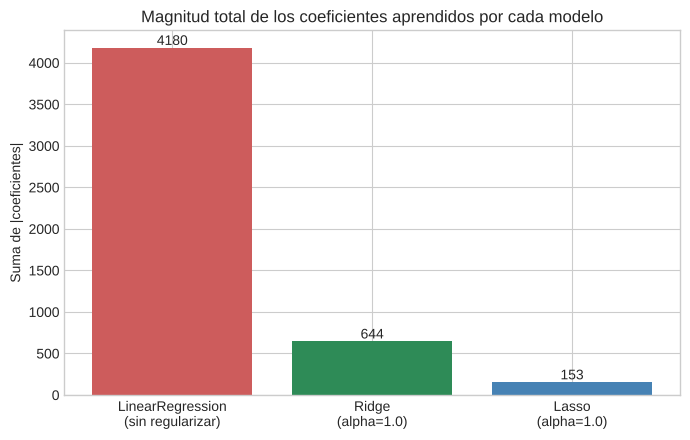

Coeficientes distintos de cero en Lasso: 36 de 65


In [ ]:
suma_abs_coefs = {
    "LinearRegression\n(sin regularizar)": np.sum(np.abs(modelo_poly_lin.coef_)),
    "Ridge\n(alpha=1.0)": np.sum(np.abs(modelo_ridge.coef_)),
    "Lasso\n(alpha=1.0)": np.sum(np.abs(modelo_lasso.coef_)),
}

fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(suma_abs_coefs.keys(), suma_abs_coefs.values(),
                 color=['indianred', 'seagreen', 'steelblue'])
ax.set_ylabel('Suma de |coeficientes|')
ax.set_title('Magnitud total de los coeficientes aprendidos por cada modelo')
for barra, valor in zip(barras, suma_abs_coefs.values()):
    ax.text(barra.get_x() + barra.get_width() / 2, valor, f"{valor:.0f}",
            ha='center', va='bottom')
plt.tight_layout()
plt.show()

print("Coeficientes distintos de cero en Lasso:", np.sum(modelo_lasso.coef_ != 0), "de", len(modelo_lasso.coef_))

La regresión lineal sin regularizar aprendió coeficientes mucho más grandes (en conjunto) que Ridge o Lasso. Coeficientes muy grandes suelen ser una señal de que el modelo está "forzando" la curva para pasar cerca de cada punto de entrenamiento, incluyendo el ruido, lo cual perjudica la generalización. Lasso, además, llevó varios coeficientes exactamente a cero: en la práctica, "descartó" esas variables por considerarlas poco útiles.


### 6.3 Buscando el mejor valor de alpha: tuneo de hiperparámetro alpha


Usamos `alpha=1.0` porque es un valor razonable para empezar, pero no hay ninguna garantía de que sea el mejor. Probemos muchos valores de `alpha` (en escala logarítmica, porque su efecto no es lineal) y grafiquemos cómo cambia el R² de entrenamiento y de prueba en cada caso.


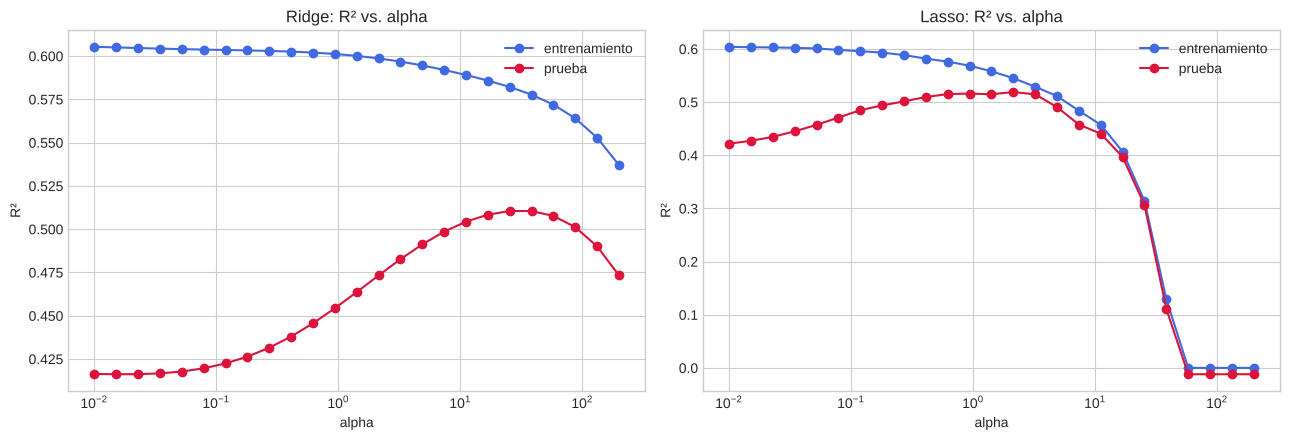

Mejor alpha para Ridge (según R² de prueba): 25.36 -> R² test = 0.510
Mejor alpha para Lasso (según R² de prueba): 2.13 -> R² test = 0.519


In [ ]:
alphas = np.logspace(-2, 2.3, 25)

ridge_train, ridge_test = [], []
lasso_train, lasso_test = [], []

for a in alphas:
    r = Ridge(alpha=a).fit(X_train_poly_s, y_train)
    l = Lasso(alpha=a, max_iter=50000).fit(X_train_poly_s, y_train)

    ridge_train.append(r2_score(y_train, r.predict(X_train_poly_s)))
    ridge_test.append(r2_score(y_test, r.predict(X_test_poly_s)))
    lasso_train.append(r2_score(y_train, l.predict(X_train_poly_s)))
    lasso_test.append(r2_score(y_test, l.predict(X_test_poly_s)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(alphas, ridge_train, marker='o', label='entrenamiento', color='royalblue')
axes[0].plot(alphas, ridge_test, marker='o', label='prueba', color='crimson')
axes[0].set_xscale('log')
axes[0].set_xlabel('alpha')
axes[0].set_ylabel('R²')
axes[0].set_title('Ridge: R² vs. alpha')
axes[0].legend()

axes[1].plot(alphas, lasso_train, marker='o', label='entrenamiento', color='royalblue')
axes[1].plot(alphas, lasso_test, marker='o', label='prueba', color='crimson')
axes[1].set_xscale('log')
axes[1].set_xlabel('alpha')
axes[1].set_ylabel('R²')
axes[1].set_title('Lasso: R² vs. alpha')
axes[1].legend()

plt.tight_layout()
plt.show()

mejor_alpha_ridge = alphas[np.argmax(ridge_test)]
mejor_alpha_lasso = alphas[np.argmax(lasso_test)]
print(f"Mejor alpha para Ridge (según R² de prueba): {mejor_alpha_ridge:.2f} -> R² test = {max(ridge_test):.3f}")
print(f"Mejor alpha para Lasso (según R² de prueba): {mejor_alpha_lasso:.2f} -> R² test = {max(lasso_test):.3f}")

**Este gráfico es una de las ideas más importantes del taller de hoy.** Fijate el patrón:

- Con `alpha` muy chico, ambos modelos se comportan casi como una regresión lineal sin regularizar: buen R² de entrenamiento, R² de prueba más bajo.
- A medida que `alpha` crece, el R² de **prueba** mejora, porque el modelo deja de sobreajustar.
- Pero si `alpha` sigue creciendo demasiado, el R² de **entrenamiento y de prueba caen juntos**: el modelo se vuelve demasiado simple (los coeficientes se achican tanto que el modelo casi no distingue entre variables) y empieza a **subajustar**.

Existe un valor de `alpha` intermedio, ni muy chico ni muy grande, donde el R² de prueba (el del conjunto de testeo) alcanza su máximo. Elegir ese punto óptimo (normalmente con validación cruzada, algo que van a ver más adelante en la materia) es el objetivo real de "ajustar" un modelo regularizado.

Este vaivén **(poca regularización → sobreajuste; demasiada regularización → subajuste)** es exactamente el tema que vamos a explorar en profundidad en la próxima sección, ahora sin el condimento extra de la regularización.


## 7. Subajuste y sobreajuste: el concepto

Definamos con precisión dos conceptos que ya insinuamos en la sección anterior:

- **Subajuste (*underfitting*):** el modelo es demasiado simple para capturar el patrón real de los datos. Ajusta mal tanto en entrenamiento como en prueba. Ejemplo extremo: predecir siempre el mismo valor constante, sin importar las variables de entrada.
- **Sobreajuste (*overfitting*):** el modelo es demasiado complejo en relación a la cantidad de datos disponibles. Ajusta muy bien (casi perfecto) los datos de entrenamiento, incluyendo su ruido particular, pero generaliza mal: su error sobre datos nuevos es mucho más alto que su error de entrenamiento.

Entre ambos extremos existe una zona de **buen ajuste**, donde el modelo captura el patrón real sin memorizar el ruido.

### ¿Por qué usar regresión lineal con polinomios de distinto grado para ilustrar esto?

Es una pregunta válida: ¿no sería más representativo usar modelos completamente distintos entre sí (por ejemplo, "una constante", "una recta", "un árbol de decisión") para mostrar subajuste y sobreajuste? En la práctica, el enfoque pedagógico más claro (y el que vamos a usar) es **mantener siempre el mismo algoritmo, `LinearRegression`, y variar únicamente la complejidad de las variables de entrada mediante `PolynomialFeatures`**. Las razones:

1. **Aislamos una sola variable de complejidad.** El grado del polinomio es un único número que controla, de forma continua y ordenada, cuánta "flexibilidad" tiene el modelo: grado 0 es una constante, grado 1 es una recta, y grados altos permiten curvas cada vez más sinuosas. Comparar modelos de familias distintas mezclaría varios factores a la vez y haría más difícil ver el fenómeno con claridad.
2. **El modelo que se ajusta sigue siendo el mismo que ya conocen (`LinearRegression`).** Lo único que cambia es la representación de los datos de entrada (agregamos $x^2$, $x^3$, etc. como nuevas columnas). Esto refuerza una idea clave: el sobreajuste no depende solo del algoritmo, sino de la relación entre la complejidad del modelo y la cantidad de datos disponibles.
3. **Se puede visualizar perfectamente en dos dimensiones.** Con una sola variable de entrada podemos graficar la curva que aprendió el modelo directamente sobre los datos, algo que no se puede hacer con la misma claridad cuando hay muchas variables (como en la Sección 5 y 6).

Por eso, sí: la regresión lineal (combinada con `PolynomialFeatures`) es el modelo apropiado y, de hecho, el estándar en la enseñanza de este tema. Es exactamente el mismo truco que usamos en la Sección 5 para generar un escenario de sobreajuste, solo que ahora en una sola variable, para poder graficarlo.


## 8. Demostración visual con una sola variable

Para poder graficar la curva ajustada, nos quedamos con una sola variable del mismo dataset de diabetes: `bmi` (índice de masa corporal), que es una de las variables más relacionadas con la progresión de la enfermedad. Usamos el **mismo dataset** que en las secciones anteriores, así que los resultados son directamente comparables.


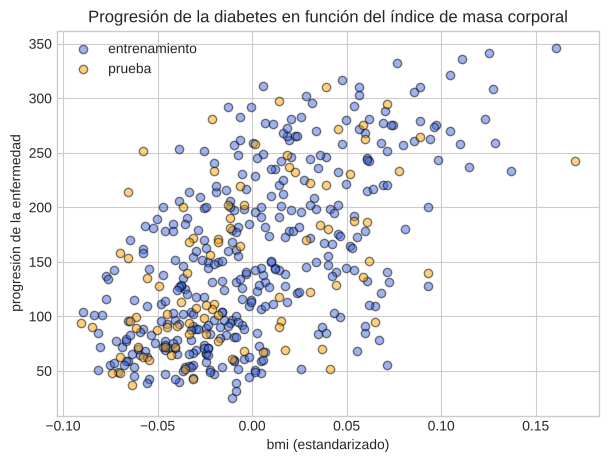

In [ ]:
X_bmi = df[['bmi']].values
y_bmi = df['target'].values

Xtr_bmi, Xte_bmi, ytr_bmi, yte_bmi = train_test_split(
    X_bmi, y_bmi, test_size=0.2, random_state=SEMILLA
)

plt.figure(figsize=(7, 5))
plt.scatter(Xtr_bmi, ytr_bmi, alpha=0.5, edgecolor='k', color='royalblue', label='entrenamiento')
plt.scatter(Xte_bmi, yte_bmi, alpha=0.5, edgecolor='k', color='orange', label='prueba')
plt.xlabel('bmi (estandarizado)')
plt.ylabel('progresión de la enfermedad')
plt.title('Progresión de la diabetes en función del índice de masa corporal')
plt.legend()
plt.show()

**Pregunta para pensar:** mirando el gráfico, ¿te parece que la relación entre `bmi` y la progresión de la enfermedad es aproximadamente lineal, o hay una curva más compleja escondida en los datos?


**Respuesta:** La tendencia general es aproximadamente lineal y creciente (a mayor `bmi`, mayor progresión), pero con muchísima dispersión: para un mismo valor de `bmi` hay pacientes con progresiones muy distintas. No se ve una curva compleja escondida; como mucho, una leve curvatura. Eso ya anticipa que agregar mucha complejidad no va a mejorar demasiado la predicción, porque buena parte de la variación es ruido o depende de otras variables.

### 8.1 Cuatro modelos, cuatro niveles de complejidad

Entrenamos cuatro versiones del mismo modelo (`LinearRegression`), variando el grado del polinomio con el que representamos a `bmi`:

- **Grado 0:** una constante (el promedio de `y` en entrenamiento). No usa la variable `bmi` para nada: subajuste extremo.
- **Grado 1:** una recta. Es el modelo de regresión lineal simple que ya conocemos.
- **Grado 6:** una curva de complejidad moderada.
- **Grado 15:** un polinomio de grado muy alto, con mucha libertad para "serpentear" entre los puntos.


In [ ]:
def ajustar_polinomio(grado, Xtr, ytr, Xte, yte, x_grid):
    # Ajusta LinearRegression sobre Xtr elevado al grado indicado (0 = constante).
    # Devuelve la prediccion sobre una grilla, mas el RMSE de train y de test.
    if grado == 0:
        pred_grid = np.full(x_grid.shape[0], ytr.mean())
        pred_tr = np.full_like(ytr, ytr.mean(), dtype=float)
        pred_te = np.full_like(yte, ytr.mean(), dtype=float)
    else:
        poly_g = PolynomialFeatures(degree=grado, include_bias=False)
        Xtr_p = poly_g.fit_transform(Xtr)
        Xte_p = poly_g.transform(Xte)
        Xg_p = poly_g.transform(x_grid)
        m = LinearRegression().fit(Xtr_p, ytr)
        pred_grid = m.predict(Xg_p)
        pred_tr = m.predict(Xtr_p)
        pred_te = m.predict(Xte_p)

    rmse_tr = mean_squared_error(ytr, pred_tr) ** 0.5
    rmse_te = mean_squared_error(yte, pred_te) ** 0.5
    return pred_grid, rmse_tr, rmse_te

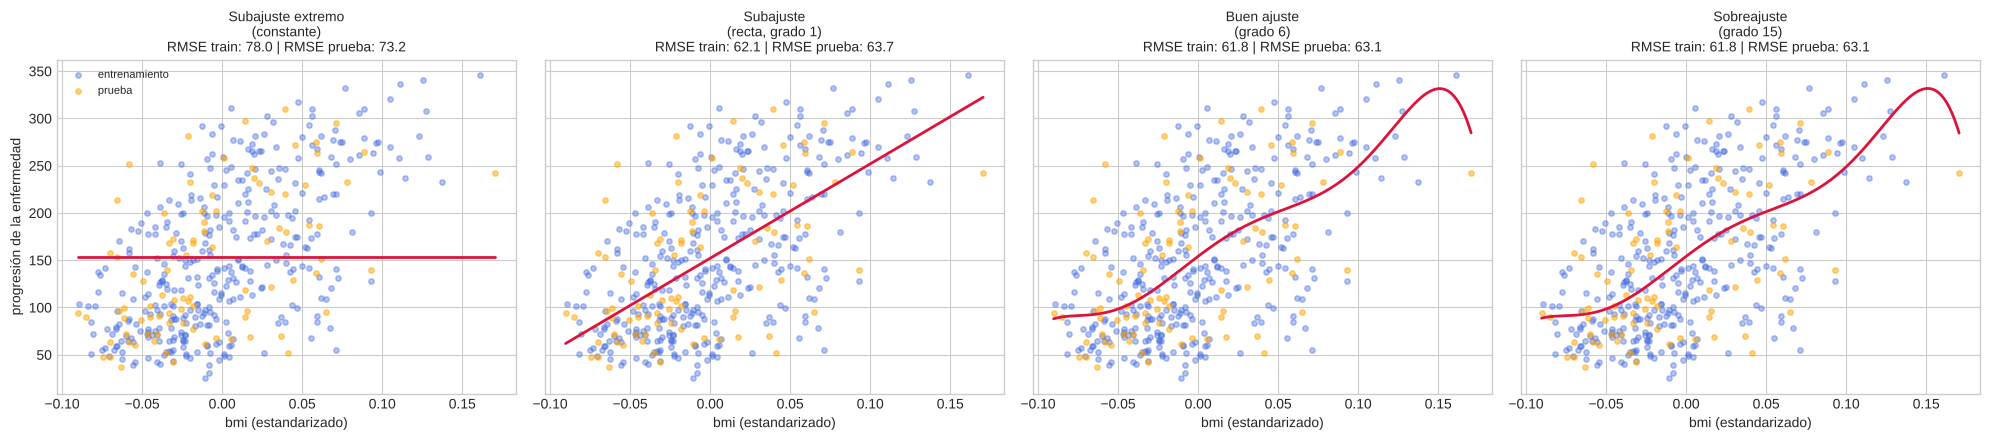

In [ ]:
grados = [0, 1, 6,15] # pruebe quitar el ,15 y ejecute para comparar los gráficos
etiquetas = ['Subajuste extremo\n(constante)', 'Subajuste\n(recta, grado 1)',
             'Buen ajuste\n(grado 6)', 'Sobreajuste\n(grado 15)']

x_grid = np.linspace(X_bmi.min(), X_bmi.max(), 300).reshape(-1, 1)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)

for ax, grado, etiqueta in zip(axes, grados, etiquetas):
    ax.scatter(Xtr_bmi, ytr_bmi, alpha=0.4, s=15, color='royalblue', label='entrenamiento')
    ax.scatter(Xte_bmi, yte_bmi, alpha=0.5, s=15, color='orange', label='prueba')

    pred_grid, rmse_tr, rmse_te = ajustar_polinomio(grado, Xtr_bmi, ytr_bmi, Xte_bmi, yte_bmi, x_grid)
    ax.plot(x_grid, pred_grid, color='crimson', linewidth=2)

    ax.set_title(f"{etiqueta}\nRMSE train: {rmse_tr:.1f} | RMSE prueba: {rmse_te:.1f}", fontsize=10)
    ax.set_xlabel('bmi (estandarizado)')

axes[0].set_ylabel('progresión de la enfermedad')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**¿Qué observamos en cada panel?**

- **Subajuste extremo (constante):** la línea roja es plana. El modelo ignora por completo la información de `bmi`. El error es alto tanto en entrenamiento como en prueba, y ambos son parecidos entre sí (no hay brecha, simplemente el modelo es malo en los dos casos).
- **Subajuste (recta):** ya mejora bastante respecto a la constante, pero sigue siendo una aproximación simple. Los errores de entrenamiento y prueba bajan juntos y quedan parecidos entre sí.
- **Buen ajuste (grado 6):** la curva sigue de cerca la tendencia general de los puntos sin perseguir cada uno de ellos en particular. Es el mejor equilibrio entre las cuatro opciones: el error de prueba es el más bajo de los cuatro modelos.
- **Sobreajuste (grado 15):** mirá el extremo derecho del gráfico: la curva se dispara de forma completamente artificial para pasar cerca de uno o dos puntos aislados. El modelo "memorizó" detalles particulares del conjunto de entrenamiento que no representan ningún patrón real, y el error de prueba se dispara.

Este último caso es un ejemplo muy claro de sobreajuste: el RMSE de entrenamiento es el más bajo de los cuatro (¡el modelo ajusta casi perfecto los datos que ya vio!), pero el RMSE de prueba es, por lejos, el más alto. Es la definición misma de un modelo que **no generaliza**.


### 8.2 La curva de complejidad

En vez de mirar solo cuatro grados sueltos, calculemos el error de entrenamiento y de prueba para **todos** los grados entre 0 y 15, y grafiquemos ambas curvas juntas.


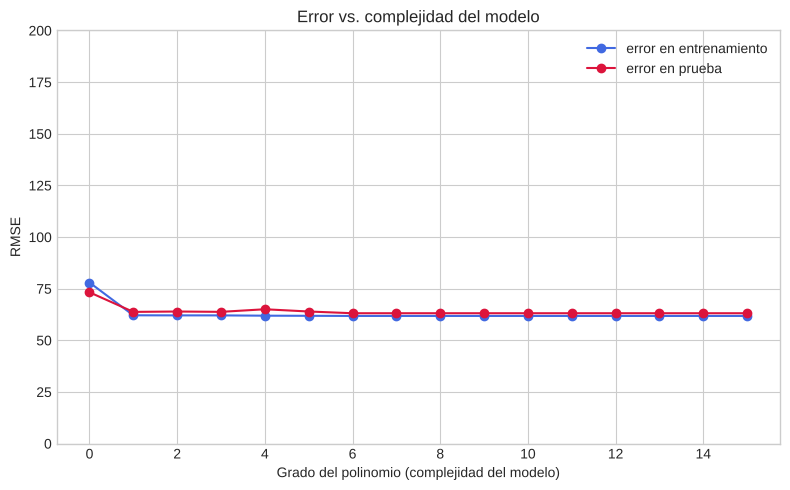

In [ ]:
grados_completos = list(range(0, 16))
rmse_train_list, rmse_test_list = [], []

for grado in grados_completos:
    _, rmse_tr, rmse_te = ajustar_polinomio(grado, Xtr_bmi, ytr_bmi, Xte_bmi, yte_bmi, x_grid)
    rmse_train_list.append(rmse_tr)
    rmse_test_list.append(rmse_te)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(grados_completos, rmse_train_list, marker='o', label='error en entrenamiento', color='royalblue')
ax.plot(grados_completos, rmse_test_list, marker='o', label='error en prueba', color='crimson')
ax.set_xlabel('Grado del polinomio (complejidad del modelo)')
ax.set_ylabel('RMSE')
ax.set_title('Error vs. complejidad del modelo')
ax.set_ylim(0, 200)
ax.legend()
plt.tight_layout()
plt.show()

Esta curva resume todo el fenómeno en una sola imagen:

- **A la izquierda** (grados bajos): el error de entrenamiento y el de prueba son altos y muy parecidos entre sí. Es la zona de **subajuste**: el modelo es demasiado simple.
- **En el medio:** el error de prueba llega a su punto más bajo. Es la zona de **buen ajuste**.
- **A la derecha** (grados altos): el error de entrenamiento sigue bajando (o se mantiene bajo), pero el error de prueba **se dispara**. Es la zona de **sobreajuste**.

Compará esta curva con la que graficamos en la Sección 6.3 (R² vs. `alpha` para Ridge y Lasso). Son, en el fondo, **la misma idea contada con otro eje**: en un caso movemos la complejidad aumentando el grado del polinomio; en el otro, la reducimos aumentando `alpha`. En ambos casos aparece la misma tensión entre ajustar bien los datos conocidos y generalizar a datos nuevos. Esa tensión tiene un nombre en Machine Learning: **el equilibrio entre sesgo y varianza** (*bias-variance tradeoff*), un tema que seguramente retomen más adelante en la materia.


## [SEMANA QUE VIENE] 9. Redes neuronales como "caja negra"

Hasta ahora vimos el fenómeno de subajuste/sobreajuste siempre con el mismo algoritmo (`LinearRegression`), variando la representación de los datos de entrada. Ahora vamos a repetir exactamente el mismo experimento con una familia de modelos completamente distinta: una **red neuronal**.

No vamos a explicar en detalle cómo funciona por dentro una red neuronal (eso excede el alcance de este taller); la vamos a tratar como una **caja negra**: le damos datos de entrada, la red ajusta automáticamente una gran cantidad de parámetros internos, y produce una predicción. Lo único que nos interesa hoy es un hecho importante: **el mismo patrón de subajuste y sobreajuste que vimos con polinomios también aparece en las redes neuronales**, y depende de decisiones similares:

- **Cuántas neuronas y capas tiene la red** (equivalente, en espíritu, al grado del polinomio: más neuronas y capas dan más "capacidad" para ajustar curvas complejas).
- **Cuánto tiempo se la entrena** (más iteraciones le dan más oportunidad de ajustar hasta el último detalle de los datos de entrenamiento).
- **Si se le aplica regularización o no** (`MLPRegressor` tiene, igual que Ridge y Lasso, un parámetro `alpha` que penaliza la magnitud de sus parámetros internos).

Vamos a usar la clase `MLPRegressor` de scikit-learn (perceptrón multicapa) sobre el **mismo dataset de una sola variable** (`bmi`) que usamos en la sección anterior, para poder comparar resultados directamente.


In [ ]:
configuraciones = [
    ("Subajuste\n(red muy chica, poco entrenada)",
     dict(hidden_layer_sizes=(2,), max_iter=50, random_state=SEMILLA,
          activation='tanh', solver='lbfgs')),
    ("Buen ajuste\n(red moderada, con regularización)",
     dict(hidden_layer_sizes=(10,), max_iter=500, random_state=SEMILLA,
          activation='tanh', solver='lbfgs', alpha=0.1)),
    ("Sobreajuste\n(red grande, sin regularizar)",
     dict(hidden_layer_sizes=(300,), max_iter=20000, random_state=SEMILLA,
          activation='tanh', solver='lbfgs', alpha=0.0)),
]

resultados_redes = []
for etiqueta, params in configuraciones:
    modelo_red = MLPRegressor(**params)
    modelo_red.fit(Xtr_bmi, ytr_bmi)
    pred_tr = modelo_red.predict(Xtr_bmi)
    pred_te = modelo_red.predict(Xte_bmi)
    rmse_tr = mean_squared_error(ytr_bmi, pred_tr) ** 0.5
    rmse_te = mean_squared_error(yte_bmi, pred_te) ** 0.5
    resultados_redes.append((etiqueta, params, modelo_red, rmse_tr, rmse_te))
    print(f"{etiqueta.splitlines()[0]:40s}  RMSE train: {rmse_tr:7.2f}   RMSE prueba: {rmse_te:7.2f}")

Subajuste                                 RMSE train:   77.95   RMSE prueba:   73.22
Buen ajuste                               RMSE train:   61.41   RMSE prueba:   63.83


Sobreajuste                               RMSE train:   59.47   RMSE prueba:  211.87


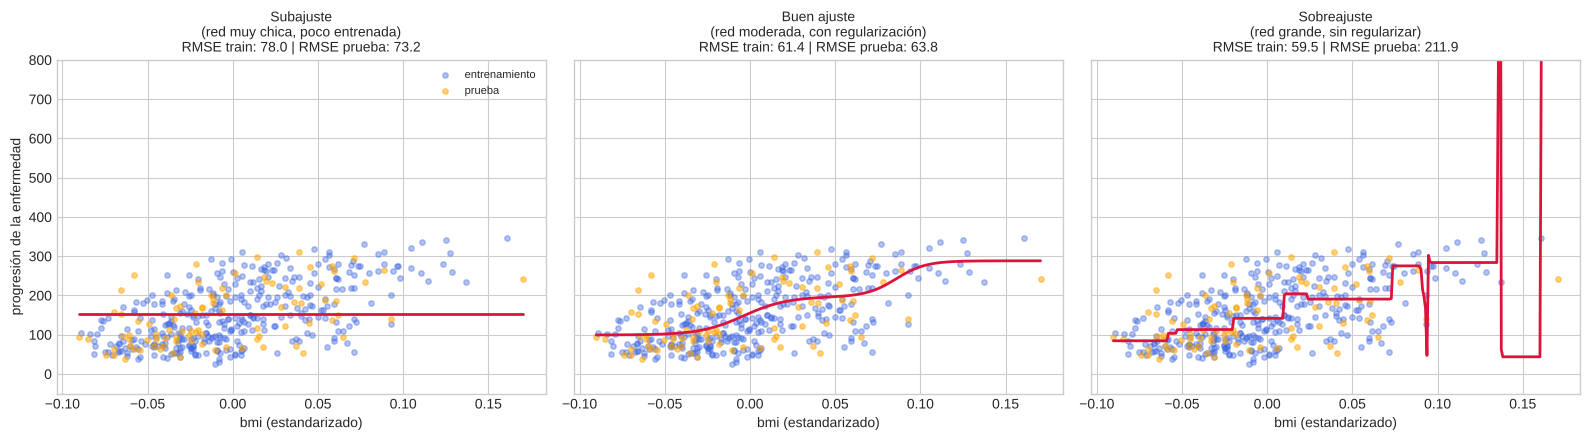

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, (etiqueta, params, modelo_red, rmse_tr, rmse_te) in zip(axes, resultados_redes):
    ax.scatter(Xtr_bmi, ytr_bmi, alpha=0.4, s=15, color='royalblue', label='entrenamiento')
    ax.scatter(Xte_bmi, yte_bmi, alpha=0.5, s=15, color='orange', label='prueba')

    pred_grid = modelo_red.predict(x_grid)
    ax.plot(x_grid, pred_grid, color='crimson', linewidth=2)

    ax.set_title(f"{etiqueta}\nRMSE train: {rmse_tr:.1f} | RMSE prueba: {rmse_te:.1f}", fontsize=10)
    ax.set_xlabel('bmi (estandarizado)')
    ax.set_ylim(-50, 800)

axes[0].set_ylabel('progresión de la enfermedad')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**¿Qué observamos?**

- **Subajuste:** con muy pocas neuronas y muy poco entrenamiento, la red apenas logra despegarse de una línea recta casi plana. No tuvo ni la capacidad ni el tiempo de aprender el patrón.
- **Buen ajuste:** con una cantidad moderada de neuronas y algo de regularización (`alpha=0.1`), la red aprende una curva suave, parecida a la que logramos con el polinomio de grado 6, y con un error de prueba similar.
- **Sobreajuste:** con una red mucho más grande, entrenada durante muchas iteraciones y **sin regularización**, la curva se vuelve errática: hace saltos y quiebres bruscos para pasar cerca de puntos aislados de entrenamiento, de forma muy similar (aunque con una forma distinta) a lo que vimos con el polinomio de grado 15. El error de entrenamiento es el más bajo de los tres casos, pero el error de prueba es, por lejos, el más alto.

La forma exacta de la curva es distinta a la de los polinomios (las redes neuronales tienen su propia manera de "doblarse"), pero el fenómeno de fondo es idéntico: **cuando la capacidad del modelo supera ampliamente lo que los datos pueden sostener, el modelo termina memorizando ruido en vez de aprender un patrón general.** Esto confirma que subajuste y sobreajuste no son un defecto exclusivo de la regresión lineal con polinomios: son un fenómeno general de Machine Learning, presente en (casi) cualquier familia de modelos, incluida esta "caja negra".


### 9.1 Comparamos todos los modelos entre sí

Para cerrar, armamos una tabla que reúne los mejores modelos que fuimos encontrando a lo largo del notebook, todos evaluados con el mismo criterio (RMSE sobre el conjunto de prueba), para tener una visión de conjunto.


In [ ]:
tabla_final = pd.DataFrame([
    {"modelo": "Polinomio grado 0 (constante) - bmi", "RMSE_prueba": ajustar_polinomio(0, Xtr_bmi, ytr_bmi, Xte_bmi, yte_bmi, x_grid)[2]},
    {"modelo": "Polinomio grado 1 (recta) - bmi", "RMSE_prueba": ajustar_polinomio(1, Xtr_bmi, ytr_bmi, Xte_bmi, yte_bmi, x_grid)[2]},
    {"modelo": "Polinomio grado 6 (buen ajuste) - bmi", "RMSE_prueba": ajustar_polinomio(6, Xtr_bmi, ytr_bmi, Xte_bmi, yte_bmi, x_grid)[2]},
    {"modelo": "Polinomio grado 15 (sobreajuste) - bmi", "RMSE_prueba": ajustar_polinomio(15, Xtr_bmi, ytr_bmi, Xte_bmi, yte_bmi, x_grid)[2]},
    {"modelo": "Red neuronal (subajuste) - bmi", "RMSE_prueba": resultados_redes[0][4]},
    {"modelo": "Red neuronal (buen ajuste) - bmi", "RMSE_prueba": resultados_redes[1][4]},
    {"modelo": "Red neuronal (sobreajuste) - bmi", "RMSE_prueba": resultados_redes[2][4]},
    {"modelo": "Ridge sobre 65 variables (dataset completo)", "RMSE_prueba": res_ridge["RMSE_test"]},
    {"modelo": "Lasso sobre 65 variables (dataset completo)", "RMSE_prueba": res_lasso["RMSE_test"]},
])
tabla_final = tabla_final.set_index('modelo').round(2).sort_values('RMSE_prueba')
tabla_final

,RMSE_prueba
modelo,
Lasso sobre 65 variables (dataset completo),50.63
Ridge sobre 65 variables (dataset completo),53.70
Polinomio grado 6 (buen ajuste) - bmi,63.08
Polinomio grado 15 (sobreajuste) - bmi,63.08
Polinomio grado 1 (recta) - bmi,63.73
Red neuronal (buen ajuste) - bmi,63.83
Red neuronal (subajuste) - bmi,73.22
Polinomio grado 0 (constante) - bmi,73.22
Red neuronal (sobreajuste) - bmi,211.87


Algunas conclusiones que se pueden leer de esta tabla:

- Los modelos "de buen ajuste" (tanto el polinomio de grado 6 como la red neuronal moderada) quedan entre los mejores de la lista, muy cerca uno del otro, a pesar de ser algoritmos completamente distintos.
- Los modelos claramente subajustados (constante, recta) y los claramente sobreajustados (grado 15, red grande sin regularizar) quedan peor posicionados que los modelos bien ajustados, aunque por razones opuestas.
- Los modelos regularizados que usan las 65 variables (Ridge y Lasso) resuelven un problema más difícil (tienen mucha más información disponible que usar) y logran errores competitivos, mostrando que la regularización les permitió aprovechar esa información sin sobreajustar.

La lección general del notebook es la misma en los tres bloques: **ni el modelo más simple ni el más complejo es siempre el mejor.** El objetivo de quien entrena un modelo es encontrar el punto de complejidad (grado del polinomio, tamaño de la red, valor de `alpha`) que logre el mejor equilibrio entre ajustar los datos conocidos y generalizar a datos nuevos.


## 10. Ejercicios para practicar

Completá las siguientes celdas de código (reemplazá `# TU CÓDIGO AQUÍ` por tu solución). Podés reutilizar las variables y funciones que ya definimos más arriba (`evaluar_modelo`, `ajustar_polinomio`, `X_train_poly_s`, `Xtr_bmi`, etc.).


### Ejercicio 1

Probá con `alpha=0.01` y con `alpha=50` en un `Ridge` entrenado sobre `X_train_poly_s` / `X_test_poly_s` (las 65 variables polinomiales). Calculá el R² de entrenamiento y de prueba para cada caso, usando la función `evaluar_modelo`. Compará ambos resultados con la fila de `Ridge (alpha=1.0)` de la tabla de la Sección 6.1. ¿Alguno de los dos generaliza mejor que `alpha=1.0`?


In [ ]:
# Ejercicio 1
resultados_ej1 = [res_ridge]   # incluimos alpha=1.0 (Sección 6.1) como referencia

for a in [0.01, 50]:
    res, _ = evaluar_modelo(
        Ridge(alpha=a), X_train_poly_s, y_train, X_test_poly_s, y_test,
        nombre=f"Ridge (alpha={a})"
    )
    resultados_ej1.append(res)

tabla_ej1 = pd.DataFrame(resultados_ej1).set_index('modelo').round(3)
tabla_ej1['brecha_R2 (train - test)'] = (tabla_ej1['R2_train'] - tabla_ej1['R2_test']).round(3)
tabla_ej1 = tabla_ej1.sort_values('R2_test', ascending=False)
tabla_ej1


,R2_train,R2_test,RMSE_train,RMSE_test,brecha_R2 (train - test)
modelo,,,,,
Ridge (alpha=50),0.574,0.509,50.866,51.004,0.065
Ridge (alpha=1.0),0.601,0.456,49.236,53.697,0.145
Ridge (alpha=0.01),0.605,0.416,48.971,55.608,0.189


**Respuesta Ejercicio 1:**

- **`alpha=0.01`** (casi sin regularizar) se comporta prácticamente igual a la `LinearRegression` de 65 variables: R² train 0,605 y R² test 0,416. Es la brecha más grande (0,19), así que sigue sobreajustando.
- **`alpha=50`** es el que **mejor generaliza**: R² test 0,509 contra 0,456 de `alpha=1.0`, y la brecha train–test baja de 0,145 a 0,065. Pierde un poco de ajuste en entrenamiento (0,574) a cambio de predecir mejor datos nuevos.

Esto coincide con el gráfico de la Sección 6.3, donde el mejor `alpha` para Ridge estaba alrededor de 25. `alpha=1.0` todavía regulariza poco para este problema.

### Ejercicio 2

En la Sección 5 usamos `PolynomialFeatures(degree=2)` sobre las 10 variables originales. Repetí ese mismo proceso (generar variables, escalar, entrenar `LinearRegression`) pero con `degree=3`. ¿Cuántas variables se generan esta vez? ¿Qué le pasa a la brecha entre el R² de entrenamiento y el de prueba en comparación con `degree=2`?


In [ ]:
# Ejercicio 2
# 1) Generamos las variables polinomiales de grado 3 (fit solo con train)
poly3 = PolynomialFeatures(degree=3, include_bias=False)
X_train_poly3 = poly3.fit_transform(X_train)
X_test_poly3 = poly3.transform(X_test)
print("Variables con PolynomialFeatures(degree=2):", X_train_poly.shape[1])
print("Variables con PolynomialFeatures(degree=3):", X_train_poly3.shape[1])
print("Filas de entrenamiento:", X_train_poly3.shape[0])

# 2) Escalamos (fit solo con train, transform en test)
scaler_poly3 = StandardScaler()
X_train_poly3_s = scaler_poly3.fit_transform(X_train_poly3)
X_test_poly3_s = scaler_poly3.transform(X_test_poly3)

# 3) Entrenamos LinearRegression sin regularizar
res_poly3_lin, modelo_poly3_lin = evaluar_modelo(
    LinearRegression(), X_train_poly3_s, y_train, X_test_poly3_s, y_test,
    nombre=f"LinearRegression ({X_train_poly3.shape[1]} variables, degree=3)"
)

tabla_ej2 = pd.DataFrame([res_baseline, res_poly_lin, res_poly3_lin]).set_index('modelo').round(3)
tabla_ej2['brecha_R2 (train - test)'] = (tabla_ej2['R2_train'] - tabla_ej2['R2_test']).round(3)
tabla_ej2


Variables con PolynomialFeatures(degree=2): 65
Variables con PolynomialFeatures(degree=3): 285
Filas de entrenamiento: 353


,R2_train,R2_test,RMSE_train,RMSE_test,brecha_R2 (train - test)
modelo,,,,,
LinearRegression (10 variables originales),0.528,0.453,53.559,53.853,0.075
"LinearRegression (65 variables, sin regularizar)",0.606,0.416,48.920,55.642,0.190
"LinearRegression (285 variables, degree=3)",0.877,-13.686,27.379,278.942,14.563


**Respuesta Ejercicio 2:** Con `degree=3` se generan **285 variables**, para solo 353 filas de entrenamiento: casi tantas columnas como datos.

- El R² de entrenamiento sube mucho (0,877), porque el modelo tiene libertad para ajustar casi cualquier cosa.
- El R² de prueba se **desploma a ≈ −13,7**, muchísimo peor que predecir siempre el promedio (que daría R² = 0). El RMSE de prueba pasa de ~56 a ~279.
- La brecha train–test pasa de 0,19 (degree=2) a **≈ 14,6**.

Es un sobreajuste extremo: el modelo memorizó el entrenamiento y es inútil sobre datos nuevos. Es justamente el escenario donde Ridge o Lasso son imprescindibles.

### Ejercicio 3

Elegí una variable distinta de `bmi` dentro del dataset de diabetes (por ejemplo, `s5` o `bp`) y repetí el experimento de la Sección 8: entrená modelos de grado 0, 1, 6 y 15 sobre esa variable, calculá el RMSE de entrenamiento y de prueba para cada uno, y graficá los cuatro paneles como hicimos antes (podés reutilizar la función `ajustar_polinomio`). ¿El comportamiento es parecido al que vimos con `bmi`?


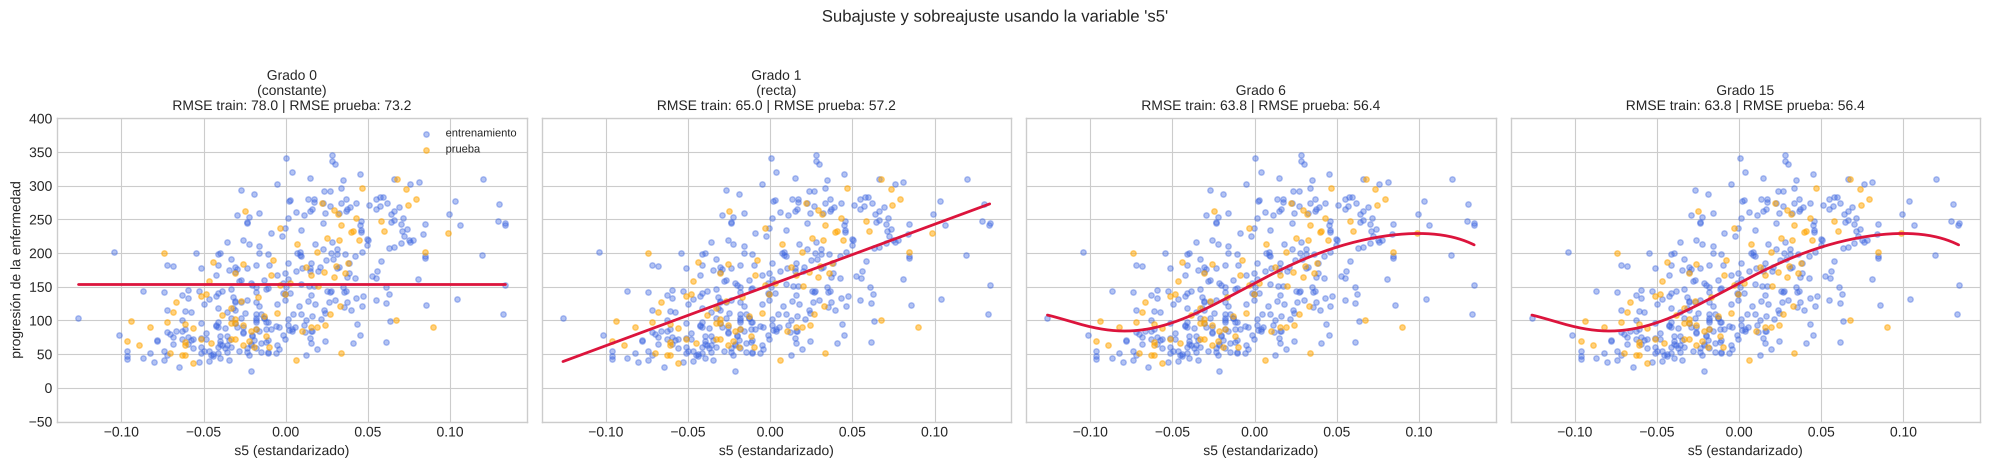

,RMSE_train,RMSE_prueba
grado,,
0,77.95,73.22
1,64.99,57.19
6,63.79,56.41
15,63.79,56.41


In [ ]:
# Ejercicio 3
variable_ej3 = 's5'   # se puede cambiar por 'bp', 'bmi', etc.

X_var = df[[variable_ej3]].values
y_var = df['target'].values

Xtr_v, Xte_v, ytr_v, yte_v = train_test_split(
    X_var, y_var, test_size=0.2, random_state=SEMILLA
)
x_grid_v = np.linspace(X_var.min(), X_var.max(), 300).reshape(-1, 1)

grados_ej3 = [0, 1, 6, 15]
etiquetas_ej3 = ['Grado 0\n(constante)', 'Grado 1\n(recta)', 'Grado 6', 'Grado 15']

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
resultados_ej3 = []

for ax, grado, etiqueta in zip(axes, grados_ej3, etiquetas_ej3):
    ax.scatter(Xtr_v, ytr_v, alpha=0.4, s=15, color='royalblue', label='entrenamiento')
    ax.scatter(Xte_v, yte_v, alpha=0.5, s=15, color='orange', label='prueba')

    pred_grid, rmse_tr, rmse_te = ajustar_polinomio(grado, Xtr_v, ytr_v, Xte_v, yte_v, x_grid_v)
    ax.plot(x_grid_v, pred_grid, color='crimson', linewidth=2)
    resultados_ej3.append({"grado": grado, "RMSE_train": rmse_tr, "RMSE_prueba": rmse_te})

    ax.set_title(f"{etiqueta}\nRMSE train: {rmse_tr:.1f} | RMSE prueba: {rmse_te:.1f}", fontsize=10)
    ax.set_xlabel(f'{variable_ej3} (estandarizado)')
    ax.set_ylim(-50, 400)

axes[0].set_ylabel('progresión de la enfermedad')
axes[0].legend(fontsize=8)
plt.suptitle(f"Subajuste y sobreajuste usando la variable '{variable_ej3}'", y=1.03)
plt.tight_layout()
plt.show()

pd.DataFrame(resultados_ej3).set_index('grado').round(2)


**Respuesta Ejercicio 3 (variable `s5`):** El comportamiento es parecido en la parte izquierda de la curva de complejidad:

- **Grado 0** subajusta (RMSE prueba 73,2, el mismo que con `bmi`, porque la constante ignora la variable).
- **Grado 1** ya mejora muchísimo (RMSE prueba 57,2): `s5` tiene una relación casi lineal con la progresión, incluso algo más predictiva que `bmi` (≈ 63,7).
- **Grado 6** mejora apenas (56,4): la curva se aplana un poco en los extremos, pero la ganancia es mínima.
- **Grado 15** da **exactamente el mismo error que grado 6**, y su curva es idéntica. No es que no haya sobreajuste: es un efecto numérico (ver la celda complementaria de abajo).

In [ ]:
# Ejercicio 3 - Complemento: ¿por qué grado 6 y grado 15 dan EXACTAMENTE el mismo error?
# Los valores de la variable son muy chicos (entre -0.1 y 0.15). Elevados a la 15 dan números del orden de 1e-15,
# que LinearRegression descarta numéricamente: en la práctica el "grado 15" se comporta como un grado ~6.
# Si escalamos las columnas polinomiales con StandardScaler, el grado alto sí puede usarse y aparece el fenómeno real.

def rmse_polinomio_escalado(grado, Xtr, ytr, Xte, yte):
    poly_g = PolynomialFeatures(degree=grado, include_bias=False)
    esc = StandardScaler()
    Xtr_p = esc.fit_transform(poly_g.fit_transform(Xtr))
    Xte_p = esc.transform(poly_g.transform(Xte))
    m = LinearRegression().fit(Xtr_p, ytr)
    return (mean_squared_error(ytr, m.predict(Xtr_p)) ** 0.5,
            mean_squared_error(yte, m.predict(Xte_p)) ** 0.5)

filas = []
for nombre, (Xtr_, Xte_, ytr_, yte_) in {'bmi': (Xtr_bmi, Xte_bmi, ytr_bmi, yte_bmi),
                                          variable_ej3: (Xtr_v, Xte_v, ytr_v, yte_v)}.items():
    for grado in [1, 6, 10, 15]:
        tr, te = rmse_polinomio_escalado(grado, Xtr_, ytr_, Xte_, yte_)
        filas.append({"variable": nombre, "grado": grado, "RMSE_train": tr, "RMSE_prueba": te})

pd.DataFrame(filas).set_index(['variable', 'grado']).round(1)


RMSE_train  RMSE_prueba
variable grado                         
bmi      1            62.1         63.7
         6            61.8         63.1
         10           61.0         65.7
         15           60.8        484.3
s5       1            65.0         57.2
         6            63.8         56.4
         10           63.6         56.5
         15           63.1         57.0

**Complemento:** al escalar las columnas polinomiales, con `bmi` el grado 15 sí **sobreajusta fuerte**: el RMSE de entrenamiento baja, pero el de prueba se dispara a varios cientos. Con `s5`, en cambio, el error casi no cambia entre grado 6 y 15. Es una variable con relación más "limpia" y bien distribuida, sin puntos aislados en los extremos que obliguen a la curva a dispararse. Conclusión: el sobreajuste depende de la complejidad del modelo **y** de cómo son los datos.

### Ejercicio 4 (desafío)

Modificá la configuración de "buen ajuste" de `MLPRegressor` en la Sección 9 (por ejemplo, cambiando `hidden_layer_sizes` a `(50,)` o `alpha` a `0.5`) y volvé a entrenar y graficar. ¿Lograste un RMSE de prueba mejor que el original? Contá con tus palabras qué cambió en la forma de la curva ajustada.


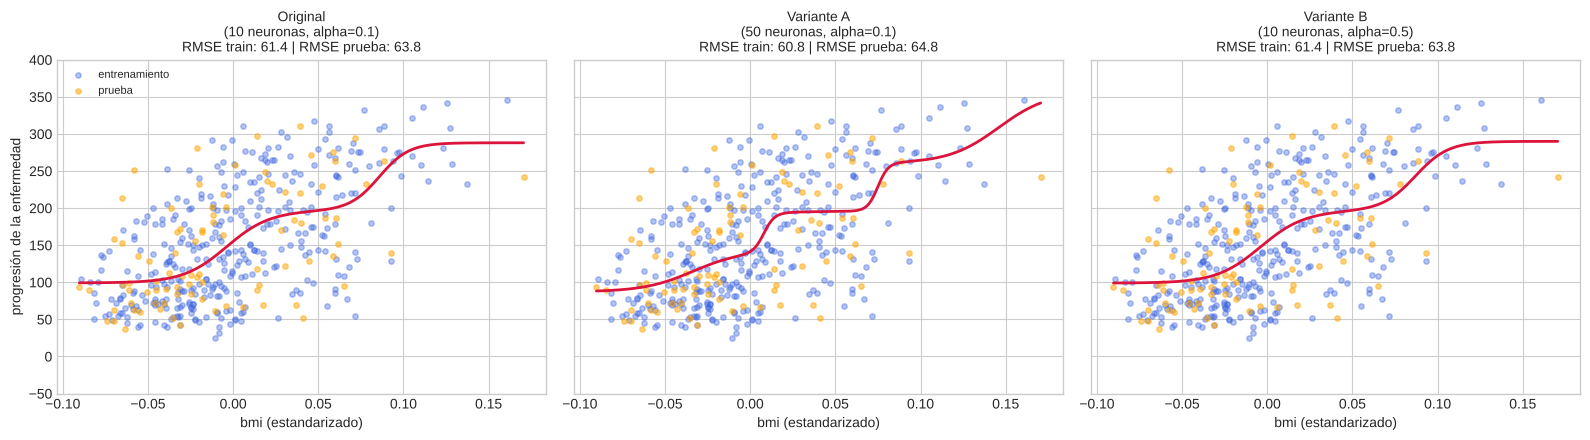

,RMSE_train,RMSE_prueba
configuración,,
"Original (10 neuronas, alpha=0.1)",61.41,63.83
"Variante A (50 neuronas, alpha=0.1)",60.81,64.79
"Variante B (10 neuronas, alpha=0.5)",61.42,63.76


In [ ]:
# Ejercicio 4
# Configuración original de "buen ajuste" + dos variantes propuestas en la consigna
config_ej4 = [
    ("Original\n(10 neuronas, alpha=0.1)",
     dict(hidden_layer_sizes=(10,), max_iter=500, random_state=SEMILLA,
          activation='tanh', solver='lbfgs', alpha=0.1)),
    ("Variante A\n(50 neuronas, alpha=0.1)",
     dict(hidden_layer_sizes=(50,), max_iter=500, random_state=SEMILLA,
          activation='tanh', solver='lbfgs', alpha=0.1)),
    ("Variante B\n(10 neuronas, alpha=0.5)",
     dict(hidden_layer_sizes=(10,), max_iter=500, random_state=SEMILLA,
          activation='tanh', solver='lbfgs', alpha=0.5)),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
resultados_ej4 = []

for ax, (etiqueta, params) in zip(axes, config_ej4):
    red = MLPRegressor(**params).fit(Xtr_bmi, ytr_bmi)
    rmse_tr = mean_squared_error(ytr_bmi, red.predict(Xtr_bmi)) ** 0.5
    rmse_te = mean_squared_error(yte_bmi, red.predict(Xte_bmi)) ** 0.5
    resultados_ej4.append({"configuración": etiqueta.replace("\n", " "),
                           "RMSE_train": rmse_tr, "RMSE_prueba": rmse_te})

    ax.scatter(Xtr_bmi, ytr_bmi, alpha=0.4, s=15, color='royalblue', label='entrenamiento')
    ax.scatter(Xte_bmi, yte_bmi, alpha=0.5, s=15, color='orange', label='prueba')
    ax.plot(x_grid, red.predict(x_grid), color='crimson', linewidth=2)
    ax.set_title(f"{etiqueta}\nRMSE train: {rmse_tr:.1f} | RMSE prueba: {rmse_te:.1f}", fontsize=10)
    ax.set_xlabel('bmi (estandarizado)')
    ax.set_ylim(-50, 400)

axes[0].set_ylabel('progresión de la enfermedad')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

pd.DataFrame(resultados_ej4).set_index('configuración').round(2)


**Respuesta Ejercicio 4:**

- **Variante A (50 neuronas):** el RMSE de prueba **empeora** levemente (64,8 contra 63,8). La curva gana "escalones": tiene tramos planos y subidas bruscas, y en el extremo derecho sigue subiendo para acercarse a los pocos puntos altos de entrenamiento. Con más neuronas la red tiene más capacidad y empieza a acercarse al sobreajuste, aunque `alpha=0.1` lo contiene.
- **Variante B (`alpha=0.5`):** el RMSE de prueba queda en 63,76, prácticamente igual al original (63,83). La curva es casi idéntica a la original: suave, en forma de "S", y plana en los extremos. Con solo 10 neuronas la red ya era simple, así que regularizar un poco más casi no cambia nada.

**Conclusión:** ninguna variante mejora de forma significativa. La configuración original ya estaba cerca del punto óptimo, y el límite lo pone el ruido de los datos (una sola variable, `bmi`, no alcanza para explicar mucho más).

## 11. Resumen

En este taller aprendiste a:

- Aplicar regularización (Ridge y Lasso) sobre un dataset real de `scikit-learn`, y a comprobar con métricas y gráficos que puede mejorar la generalización de un modelo.
- Definir con precisión los conceptos de **subajuste** y **sobreajuste**.
- Entender por qué la regresión lineal combinada con `PolynomialFeatures` es la forma más clara de ilustrar estos conceptos: mantiene fijo el algoritmo y varía únicamente la complejidad de la representación de los datos.
- Leer una curva de "error vs. complejidad del modelo" y reconocer en ella las zonas de subajuste, buen ajuste y sobreajuste.
- Reconocer que el mismo fenómeno aparece también en modelos tratados como "caja negra", como las redes neuronales (`MLPRegressor`), y que depende de decisiones análogas: capacidad del modelo (neuronas y capas), cantidad de entrenamiento, y regularización.
- Comparar modelos de familias distintas usando un mismo criterio objetivo (el error sobre el conjunto de prueba).

Cualquier duda, consultá con la profe Ana Laura.
